In [1]:
import numpy as np
import networkx as nx
from scipy.linalg import eig
from heapq import heappush, heappop
from collections import defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import time

# -------------------------
# Funciones base
# -------------------------

def get_graph(edges, nodes):
    g = nx.Graph()
    g.add_edges_from(edges)
    g.add_nodes_from(nodes)
    return g


def matrix_prod_trace(A, B):
    n = len(A)
    diag_sum = 0
    for i in range(n):
        diag_sum += np.matmul(A[i, :], B[:, i])
    return diag_sum


def hash_p_stable(projection, r):
    if r <= 0:
        return 0
    b = np.random.uniform(0, r)
    return int(np.floor((projection + b) / r))


def get_erdos_renyi_graph(n, p):
    while True:
        g = nx.erdos_renyi_graph(n, p)
        if g.number_of_edges() > 0:
            return g

def get_adjacency(g, N):
    g = g.copy()
    g.remove_edges_from(nx.selfloop_edges(g))
    nodes_order = list(sorted(g.nodes()))
 
    A = nx.adjacency_matrix(
        g,
        nodelist=nodes_order,
        weight="weight"
    ).toarray().astype(float)

    M = A.shape[0]
    A = np.pad(A, [(0, N - M), (0, N - M)], mode="constant")

    np.fill_diagonal(A, 0)

    return A

def aggregate(g1, g2, N):
    A1 = get_adjacency(g1, N)
    A2 = get_adjacency(g2, N)

    A = A1 + A2   # suma de pesos

    np.fill_diagonal(A, 0)

    return nx.from_numpy_array(A)

def total_edge_weight(g):
    return sum(data.get("weight", 1.0) for _, _, data in g.edges(data=True))

def von_newmann_entropy(g):
    g = g.copy()
    g.remove_edges_from(nx.selfloop_edges(g))

    total_w = total_edge_weight(g)

    if total_w <= 1e-12:
        return 0.0

    L = nx.laplacian_matrix(g, weight="weight").toarray().astype(float)
    rho = L / (2.0 * total_w)

    eigvals = np.linalg.eigvalsh(rho)
    eigvals[eigvals < 1e-12] = 0.0

    s = eigvals.sum()
    if s <= 1e-12:
        return 0.0

    eigvals = eigvals / s
    eigvals = eigvals[eigvals > 1e-12]

    return float(-np.sum(eigvals * np.log2(eigvals)))

def js_divergence(g1, g2, N):
    h_mix = von_newmann_entropy(aggregate(g1, g2, N))
    h_avg = (von_newmann_entropy(g1) + von_newmann_entropy(g2)) / 2
    val = max(h_mix - h_avg, 0.0)
    return np.sqrt(val)

def get_bucket_id_for_graph(g, random_graphs, B, projection_ranges, N_pad):
    bucket_id = ""

    A = get_adjacency(g, N_pad)

    for k, erg in enumerate(random_graphs):
        A_er = get_adjacency(erg, N_pad)

        proj = matrix_prod_trace(A, A_er)

        min_proj, max_proj = projection_ranges[k]
        r = (max_proj - min_proj) / B

        hash_bin = hash_p_stable(proj, r)
        bucket_id += f"{hash_bin}_"

    return bucket_id

def aggregate_many(graph_list, N):
    A_sum = np.zeros((N, N))

    for g in graph_list:
        A_sum += get_adjacency(g, N)

    np.fill_diagonal(A_sum, 0)

    return nx.from_numpy_array(A_sum)

def aggregate_many_weighted(graph_list, N):
    A_sum = np.zeros((N, N))

    for g in graph_list:
        A_sum += get_adjacency(g, N)

    np.fill_diagonal(A_sum, 0)
    return nx.from_numpy_array(A_sum)

def quality(active, clusters, h_total=None, N_pad=None):
    active = list(active)

    if len(active) == 0:
        return 0.0

    if N_pad is None:
        N_pad = max(g.number_of_nodes() for g in clusters.values())

    active_graphs = [clusters[i] for i in active]

    if h_total is None:
        A_agg_graph = aggregate_many_weighted(active_graphs, N_pad)
        h_total = von_newmann_entropy(A_agg_graph)

    if h_total <= 1e-12:
        return np.nan

    H_C = np.mean([
        von_newmann_entropy(g)
        for g in active_graphs
    ])

    return float(1.0 - H_C / h_total)

def refill_heap_global(active, clusters, N_pad):
    """
    Si no hay pares candidatos dentro de buckets,
    construye un heap global con todos los clusters activos.
    """
    heap = []
    active_list = list(active)

    for a in range(len(active_list)):
        for b in range(a + 1, len(active_list)):
            i = active_list[a]
            j = active_list[b]

            dist = js_divergence(clusters[i], clusters[j], N_pad)
            heappush(heap, (dist, i, j))

    return heap

def has_bucket_candidates(bucket_members, active):
    for members in bucket_members.values():
        alive = [x for x in members if x in active]
        if len(alive) >= 2:
            return True
    return False

In [2]:
edges_file = "data/FAO_Multiplex_Trade/Dataset/fao_trade_multiplex.edges"
layers_file = "data/FAO_Multiplex_Trade/Dataset/fao_trade_layers.txt"

layer_labels = {}
with open(layers_file, 'r') as f:
    next(f) # skip header
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 2:
            layer_labels[int(parts[0])] = parts[1]

MAX_LAYERS = len(layer_labels)
fao_graphs = {i: nx.Graph() for i in range(1, MAX_LAYERS + 1)}

with open(edges_file, 'r') as f:
    for line in f:
        parts = line.strip().split()
        layer_id = int(parts[0])
        if layer_id <= MAX_LAYERS:
            u, v, w = int(parts[1]), int(parts[2]), float(parts[3])
            # Llenamos la red insertando aristas. 
            fao_graphs[layer_id].add_edge(u, v, weight=w)

graphs_fao = [fao_graphs[i] for i in range(1, MAX_LAYERS + 1) if fao_graphs[i].number_of_edges() > 0]
# Generamos un label real para los nodos de hojas si quisiéramos
labels_fao = [layer_labels.get(i, f"L{i}") for i in range(1, MAX_LAYERS + 1) if fao_graphs[i].number_of_edges() > 0]

graphs = graphs_fao

N_pad = max(g.number_of_nodes() for g in graphs)

print(f"Gráficos cargados y válidos: {len(graphs_fao)} capas seleccionadas.")

Gráficos cargados y válidos: 364 capas seleccionadas.


In [3]:
N_pad = max(g.number_of_nodes() for g in graphs)

A_agg = aggregate_many(graphs, N_pad)

print("edges:", A_agg.number_of_edges())
print("total weight:", total_edge_weight(A_agg))
print("entropy:", von_newmann_entropy(A_agg))

edges: 13309
total weight: 800639768.0
entropy: 6.093470398521858


In [4]:
def build_lsh_buckets(graphs, num_proj=5, B=40, p_er=0.8):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    bucket_ids = [""] * num_graphs
    random_graphs = []
    projection_ranges = []

    for k in tqdm(range(num_proj), desc="LSH projections"):
        erg = get_erdos_renyi_graph(N_pad, p_er)
        random_graphs.append(erg)

        A_er = get_adjacency(erg, N_pad)

        projections = []

        for g in graphs:
            A = get_adjacency(g, N_pad)
            proj = matrix_prod_trace(A, A_er)
            projections.append(proj)

        min_proj = min(projections)
        max_proj = max(projections)

        projection_ranges.append((min_proj, max_proj))

        r = (max_proj - min_proj) / B

        for i in range(num_graphs):
            hash_bin = hash_p_stable(projections[i], r)
            bucket_ids[i] += f"{hash_bin}_"

    buckets = defaultdict(list)

    for i, bid in enumerate(bucket_ids):
        buckets[bid].append(i)

    return buckets, bucket_ids, random_graphs, projection_ranges

In [5]:
def hierarchical_bucket_heap_dynamic(
    graphs,
    buckets,
    bucket_ids,
    random_graphs,
    projection_ranges,
    B,
    epsilon=np.inf
):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    active = set(range(num_graphs))
    clusters = {i: graphs[i] for i in range(num_graphs)}

    cluster_bucket = {i: bucket_ids[i] for i in range(num_graphs)}

    bucket_members = defaultdict(set)
    for bid, indices in buckets.items():
        bucket_members[bid].update(indices)

    A_agg_graph = aggregate_many_weighted(
        [clusters[i] for i in active],
        N_pad
    )
    h_total = von_newmann_entropy(A_agg_graph)

    heap = []

    for bid, members in bucket_members.items():
        members = list(members)

        for a in range(len(members)):
            for b in range(a + 1, len(members)):
                i = members[a]
                j = members[b]

                dist = js_divergence(clusters[i], clusters[j], N_pad)
                heappush(heap, (dist, i, j))

    Z = []
    next_cluster_id = num_graphs
    global_mode = False

    while len(active) > 1:

        # Si LSH ya no produce candidatos, pasamos a clustering global normal
        if not global_mode and not has_bucket_candidates(bucket_members, active):
            global_mode = True
            heap = refill_heap_global(active, clusters, N_pad)

        if len(heap) == 0:
            if global_mode:
                heap = refill_heap_global(active, clusters, N_pad)
            else:
                break

        dist, i, j = heappop(heap)

        if i not in active or j not in active:
            continue

        # En modo LSH solo aceptamos pares dentro del mismo bucket
        if not global_mode and cluster_bucket[i] != cluster_bucket[j]:
            continue

        if dist > epsilon:
            break

        same_bucket = cluster_bucket[i] == cluster_bucket[j]

        old_bucket_i = cluster_bucket[i]
        old_bucket_j = cluster_bucket[j]

        new_id = next_cluster_id
        next_cluster_id += 1

        new_graph = aggregate(clusters[i], clusters[j], N_pad)

        active.remove(i)
        active.remove(j)

        bucket_members[old_bucket_i].discard(i)
        bucket_members[old_bucket_j].discard(j)

        clusters[new_id] = new_graph
        active.add(new_id)

        new_bucket_id = get_bucket_id_for_graph(
            new_graph,
            random_graphs=random_graphs,
            B=B,
            projection_ranges=projection_ranges,
            N_pad=N_pad
        )

        cluster_bucket[new_id] = new_bucket_id
        bucket_members[new_bucket_id].add(new_id)

        q = quality(
            active=active,
            clusters=clusters,
            h_total=h_total,
            N_pad=N_pad
        )

        Z.append([
            i,
            j,
            dist,
            q,
            new_id,
            new_bucket_id,
            same_bucket,
            global_mode
        ])

        if global_mode:
            for other in list(active):
                if other == new_id:
                    continue

                new_dist = js_divergence(
                    clusters[new_id],
                    clusters[other],
                    N_pad
                )

                heappush(heap, (new_dist, new_id, other))

        else:
            for other in list(bucket_members[new_bucket_id]):
                if other == new_id:
                    continue

                if other not in active:
                    continue

                new_dist = js_divergence(
                    clusters[new_id],
                    clusters[other],
                    N_pad
                )

                heappush(heap, (new_dist, new_id, other))

    return Z, clusters, active, bucket_members

In [6]:
def shclust_heap_dynamic(graphs, num_proj=5, B=40, epsilon=np.inf):
    buckets, bucket_ids, random_graphs, projection_ranges = build_lsh_buckets(
        graphs,
        num_proj=num_proj,
        B=B
    )

    Z, clusters, active, bucket_members = hierarchical_bucket_heap_dynamic(
        graphs=graphs,
        buckets=buckets,
        bucket_ids=bucket_ids,
        random_graphs=random_graphs,
        projection_ranges=projection_ranges,
        B=B,
        epsilon=epsilon
    )

    return Z, clusters, active, bucket_members, bucket_ids

In [7]:

start = time.time()

Z, clusters, active, bucket_members, bucket_ids = shclust_heap_dynamic(
    graphs,
    num_proj=5,
    B=100,
    epsilon=np.inf
)

time_lsh = time.time() - start

print("Tiempo LSH:", time_lsh)

print("\nBucket IDs:")
for i, bid in enumerate(bucket_ids):
    print(f"Graph {i}: {bid}")

print("\nMerges:")
for row in Z:
    print(row)

print("\nFinal clusters:")
print(clusters)

LSH projections: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:08<00:00,  1.68s/it]


Tiempo LSH: 2695.41188621521

Bucket IDs:
Graph 0: 8_9_8_10_7_
Graph 1: 2_1_2_2_2_
Graph 2: 28_32_33_38_31_
Graph 3: 14_15_16_18_15_
Graph 4: 18_20_21_27_23_
Graph 5: 26_28_25_37_34_
Graph 6: 3_3_3_3_2_
Graph 7: 14_15_13_19_17_
Graph 8: 2_2_1_2_2_
Graph 9: 2_1_2_1_2_
Graph 10: 6_6_6_7_6_
Graph 11: 3_3_3_5_3_
Graph 12: 28_30_24_35_35_
Graph 13: 9_12_11_16_14_
Graph 14: 2_3_3_3_3_
Graph 15: 0_0_1_1_0_
Graph 16: 1_2_2_2_2_
Graph 17: 0_1_1_1_0_
Graph 18: 1_2_1_2_2_
Graph 19: 7_8_8_10_8_
Graph 20: 1_2_2_2_2_
Graph 21: 1_2_1_1_1_
Graph 22: 0_0_0_0_0_
Graph 23: 20_26_26_34_23_
Graph 24: 3_2_3_2_3_
Graph 25: 1_0_0_0_0_
Graph 26: 3_3_3_4_4_
Graph 27: 5_5_6_7_7_
Graph 28: 9_9_9_12_10_
Graph 29: 15_18_18_22_20_
Graph 30: 1_1_2_2_2_
Graph 31: 5_5_5_6_6_
Graph 32: 3_4_4_4_4_
Graph 33: 0_0_1_1_1_
Graph 34: 1_1_1_1_1_
Graph 35: 4_4_4_5_5_
Graph 36: 4_4_5_6_6_
Graph 37: 23_21_21_28_25_
Graph 38: 0_1_1_0_1_
Graph 39: 1_1_1_1_1_
Graph 40: 1_1_2_1_2_
Graph 41: 3_2_3_3_3_
Graph 42: 3_3_3_4_4_
Graph 43: 0_

In [25]:
def plot_quality_by_merge(Z):
    df = pd.DataFrame(
        Z,
        columns=[
            "cluster_i",
            "cluster_j",
            "dist",
            "q",
            "new_cluster_id",
            "new_bucket_id",
            "same_bucket",
            "global_mode"
        ]
    )

    df["merge"] = range(1, len(df) + 1)

    # Encontrar máximo
    idx_max = df.shape[0] - 4 #df["q"].idxmax()
    x_max = df.loc[idx_max, "merge"]
    y_max = df.loc[idx_max, "q"]

    plt.figure(figsize=(8, 5))

    # Línea continua
    plt.plot(df["merge"], df["q"], color="black", linestyle="-")

    # Punto en el máximo
    plt.scatter(x_max, y_max, color="black" , zorder=5)

    #plt.xlabel("Merge")
    plt.ylabel("q(C)")
    #plt.title("Quality q(C) - hierarchical clustering normal")
    plt.grid(True)

    # # Opcional: anotar el punto máximo
    # plt.annotate(
    #     f"max={y_max:.3f}",
    #     (x_max, y_max),
    #     textcoords="offset points",
    #     xytext=(5,5)
    # )

    plt.show()

    return df

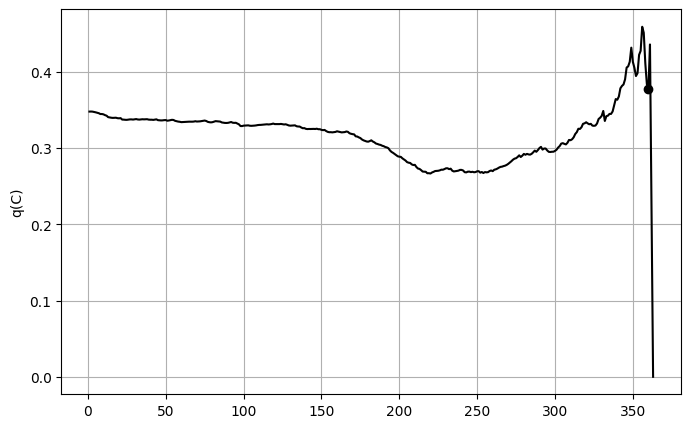

,cluster_i,cluster_j,dist,q,new_cluster_id,new_bucket_id,same_bucket,global_mode,merge
0,45,244,0.000000,0.347900,364,0_0_1_1_0_,True,False,1
1,76,57,0.000000,0.347975,365,0_1_0_0_0_,True,False,2
2,128,127,0.000000,0.347829,366,0_0_0_0_0_,True,False,3
3,130,133,0.000000,0.347413,367,1_1_0_0_0_,True,False,4
4,131,276,0.000000,0.346925,368,0_0_0_0_0_,True,False,5
...,...,...,...,...,...,...,...,...,...
358,721,71,0.828758,0.383759,722,2_4_4_5_4_,False,True,359
359,722,720,0.789874,0.377792,723,5_8_9_12_11_,False,True,360
360,723,719,0.786735,0.435954,724,1043_1074_1110_1336_1222_,False,True,361
361,230,286,1.112505,0.225447,725,1_1_1_1_1_,False,True,362


In [26]:
df_q = plot_quality_by_merge(Z)
df_q

# General

In [10]:


def hierarchical_clustering_heap(graphs, epsilon=np.inf):
    """
    Clustering jerárquico normal, sin buckets LSH.

    Usa:
        dist(g_i, g_j) = Jensen-Shannon distance

    Z guarda:
        [cluster_i, cluster_j, dist, q, new_cluster_id]
    """

    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    active = set(range(num_graphs))
    clusters = {i: graphs[i] for i in range(num_graphs)}

    # h(A_agg) fijo sobre todos los grafos originales
    A_agg_graph = aggregate_many(
        [clusters[i] for i in active],
        N_pad
    )
    h_total = von_newmann_entropy(A_agg_graph)

    heap = []

    # Inicializar heap con todos los pares globales
    active_list = list(active)

    for a in range(len(active_list)):
        for b in range(a + 1, len(active_list)):
            i = active_list[a]
            j = active_list[b]

            dist = js_divergence(clusters[i], clusters[j], N_pad)
            heappush(heap, (dist, i, j))

    Z = []
    next_cluster_id = num_graphs

    while len(active) > 1 and len(heap) > 0:
        dist, i, j = heappop(heap)

        # Lazy deletion
        if i not in active or j not in active:
            continue

        if dist > epsilon:
            break

        new_id = next_cluster_id
        next_cluster_id += 1

        new_graph = aggregate(clusters[i], clusters[j], N_pad)

        active.remove(i)
        active.remove(j)

        clusters[new_id] = new_graph
        active.add(new_id)

        q = quality(
            active=active,
            clusters=clusters,
            h_total=h_total,
            N_pad=N_pad
        )

        Z.append([
            i,
            j,
            dist,
            q,
            new_id
        ])

        # Calcular distancia del nuevo cluster contra todos los activos
        for other in list(active):
            if other == new_id:
                continue

            new_dist = js_divergence(
                clusters[new_id],
                clusters[other],
                N_pad
            )

            heappush(heap, (new_dist, new_id, other))

    return Z, clusters, active

In [11]:
start = time.time()

Z_normal, clusters_normal, active_normal = hierarchical_clustering_heap(
    graphs,
    epsilon=np.inf
)

time_normal = time.time() - start

print("Tiempo normal:", time_normal)

Tiempo normal: 8211.970870494843


In [22]:

# print("\nMerges:")
# for row in Z_normal:
#     print(row)

# print("\nFinal clusters:")
# print(clusters_normal)

In [20]:
def plot_quality_normal(Z_normal):
    df = pd.DataFrame(
        Z_normal,
        columns=[
            "cluster_i",
            "cluster_j",
            "dist",
            "q",
            "new_cluster_id"
        ]
    )

    df["merge"] = range(1, len(df) + 1)

    # Encontrar máximo
    idx_max = df.shape[0] - 4 #df["q"].idxmax()
    x_max = df.loc[idx_max, "merge"]
    y_max = df.loc[idx_max, "q"]

    plt.figure(figsize=(8, 5))

    # Línea continua
    plt.plot(df["merge"], df["q"], color="black", linestyle="-")

    # Punto en el máximo
    plt.scatter(x_max, y_max, color="black" , zorder=5)

    #plt.xlabel("Merge")
    plt.ylabel("q(C)")
    #plt.title("Quality q(C) - hierarchical clustering normal")
    plt.grid(True)

    # # Opcional: anotar el punto máximo
    # plt.annotate(
    #     f"max={y_max:.3f}",
    #     (x_max, y_max),
    #     textcoords="offset points",
    #     xytext=(5,5)
    # )

    plt.show()

    return df

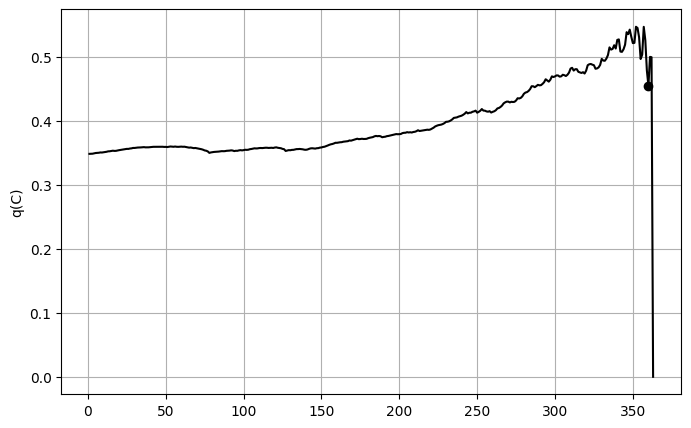

,cluster_i,cluster_j,dist,q,new_cluster_id,merge
0,0,46,0.000000,0.348787,364,1
1,1,57,0.000000,0.348906,365,2
2,2,344,0.000000,0.349030,366,3
3,3,17,0.000000,0.349519,367,4
4,4,14,0.000000,0.350104,368,5
...,...,...,...,...,...,...
358,718,240,0.916465,0.479214,722,359
359,722,721,0.882344,0.455257,723,360
360,723,720,0.986566,0.500507,724,361
361,724,184,1.236124,0.500000,725,362


In [21]:
df_normal = plot_quality_normal(Z_normal)
df_normal

In [27]:
def compare_quality_curves(Z_lsh, Z_normal):
    df_lsh = pd.DataFrame(
        Z_lsh,
        columns=[
            "cluster_i",
            "cluster_j",
            "dist",
            "q",
            "new_cluster_id",
            "new_bucket_id",
            "same_bucket",
            "global_mode"
        ]
    )

    df_normal = pd.DataFrame(
        Z_normal,
        columns=[
            "cluster_i",
            "cluster_j",
            "dist",
            "q",
            "new_cluster_id"
        ]
    )

    df_lsh["merge"] = range(1, len(df_lsh) + 1)
    df_normal["merge"] = range(1, len(df_normal) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(df_normal["merge"], df_normal["q"], color="darkblue", linestyle="-", label="hclust")
    plt.plot(df_lsh["merge"], df_lsh["q"], color="red", linestyle="-.", label="shclust")
    #plt.xlabel("Merge")
    plt.ylabel("q(C)")
    #plt.title("Comparación de q(C): normal vs LSH")
    plt.legend()
    plt.grid(True)
    plt.show()

    return df_lsh, df_normal

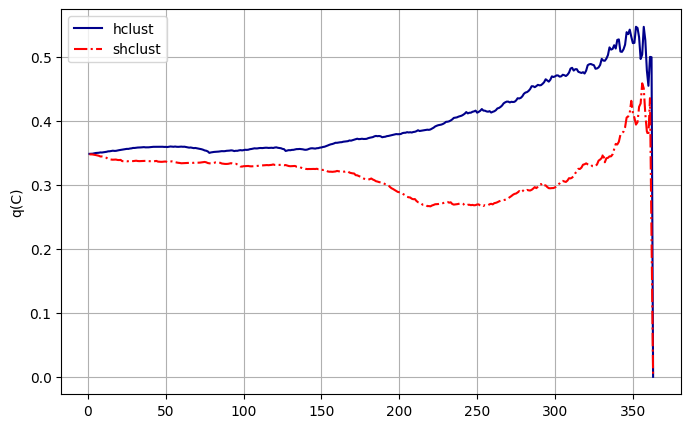

In [28]:
df_lsh, df_normal = compare_quality_curves(Z, Z_normal)

In [17]:
print("Tiempo normal:", time_normal)
print("Tiempo LSH:", time_lsh)
print("Speedup:", time_normal / time_lsh if time_lsh > 0 else np.inf)

Tiempo normal: 8211.970870494843
Tiempo LSH: 2695.41188621521
Speedup: 3.0466478657648737
